<a href="https://colab.research.google.com/github/Alk207-lab/-Machine-learning-projects-Sem1/blob/main/Ex5email_spam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Email Spam Classification using Machine Learning

**Goal:** Train a classification model to predict whether an email is spam or not spam using `emails.csv`.

### Dataset columns
- `text`: email subject/body text (input feature).
- `spam`: target label (`1` = spam, `0` = not spam).

**Algorithm used:** TF-IDF + Multinomial Naive Bayes.  
This is a beginner-friendly text-classification pipeline. TF-IDF converts words into numerical features; Naive Bayes learns which word patterns are associated with spam.

> Run the notebook in Google Colab or Jupyter. Upload `emails.csv` when prompted, or keep it in the same folder as the notebook.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

## 2. Load the CSV dataset

In [8]:
import pandas as pd
import os
from google.colab import files

file_path = "emails.csv"

# If the file isn't in the local directory, prompt the user to upload it
if not os.path.exists(file_path):
    print("emails.csv not found in the current directory. Please upload it below:")
    uploaded = files.upload()
    for name in uploaded.keys():
        if name.endswith('.csv'):
            file_path = name
            break

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

emails.csv not found in the current directory. Please upload it below:


Saving emails.csv to emails.csv
Dataset shape: (5728, 2)


,text,spam
0,Subject: naturally irresistible your corporate...,1
1,Subject: the stock trading gunslinger fanny i...,1
2,Subject: unbelievable new homes made easy im ...,1
3,Subject: 4 color printing special request add...,1
4,"Subject: do not have money , get software cds ...",1



Column names: ['text', 'spam']

Data types:
text    object
spam     int64
dtype: object


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 3. Understand and clean the data

In [9]:
print("Missing values:")
print(df.isnull().sum())

print("\\nDuplicate email texts:", df["text"].duplicated().sum())
print("\\nTarget label counts (0 = not spam, 1 = spam):")
print(df["spam"].value_counts().sort_index())

# Remove rows with missing text or target, and duplicate email texts.
df = df.dropna(subset=["text", "spam"]).copy()
df["text"] = df["text"].astype(str)
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

# Ensure labels are numeric integers.
df["spam"] = pd.to_numeric(df["spam"], errors="coerce")
df = df.dropna(subset=["spam"])
df["spam"] = df["spam"].astype(int)

print("\\nCleaned dataset shape:", df.shape)
print(df["spam"].value_counts().sort_index())

Missing values:
text    0
spam    0
dtype: int64
\nDuplicate email texts: 33
\nTarget label counts (0 = not spam, 1 = spam):
spam
0    4360
1    1368
Name: count, dtype: int64
\nCleaned dataset shape: (5695, 2)
spam
0    4327
1    1368
Name: count, dtype: int64


## 4. Explore the target distribution

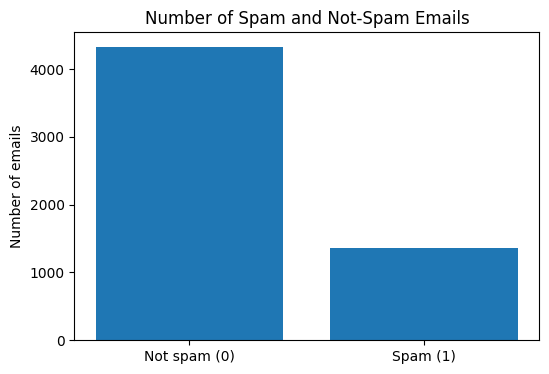

Class proportions:
spam
0    75.98%
1    24.02%
Name: proportion, dtype: object


In [10]:
counts = df["spam"].value_counts().sort_index()
labels = ["Not spam (0)", "Spam (1)"]

plt.figure(figsize=(6, 4))
plt.bar(labels, [counts.get(0, 0), counts.get(1, 0)])
plt.title("Number of Spam and Not-Spam Emails")
plt.ylabel("Number of emails")
plt.show()

print("Class proportions:")
print((df["spam"].value_counts(normalize=True) * 100).round(2).astype(str) + "%")

### What the analysis tells us
The dataset has one text input column and one binary target. The original file contains 5,728 rows, with 4,360 not-spam emails and 1,368 spam emails (about 76.1% vs 23.9%). There are 33 duplicate text entries and no missing values in the original file. The cleaning step removes duplicate texts before model training.

Because the classes are imbalanced, accuracy alone may be misleading. We will also inspect precision, recall, F1-score, and the confusion matrix.

## 5. Split the data into training and testing sets

In [11]:
X = df["text"]
y = df["spam"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4556
Testing samples: 1139


## 6. Build and train the classification model

In [12]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=30000,
        ngram_range=(1, 2)
    )),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


## 7. Make predictions and evaluate the model

In [13]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\\nDetailed classification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Not spam", "Spam"],
    zero_division=0
))

Accuracy : 0.9631 (96.31%)
Precision: 1.0000
Recall   : 0.8467
F1-score : 0.9170
\nDetailed classification report:
              precision    recall  f1-score   support

    Not spam       0.95      1.00      0.98       865
        Spam       1.00      0.85      0.92       274

    accuracy                           0.96      1139
   macro avg       0.98      0.92      0.95      1139
weighted avg       0.96      0.96      0.96      1139



## 8. Confusion matrix

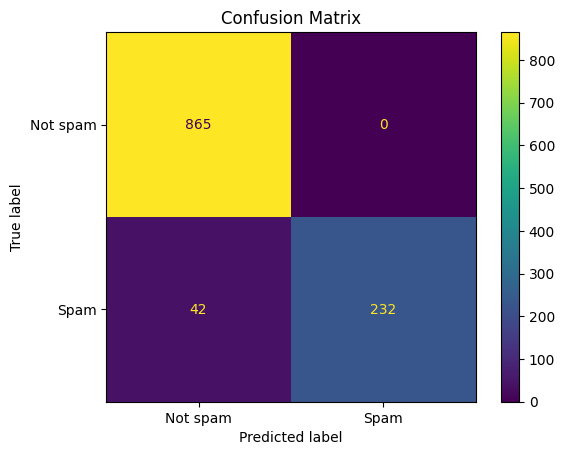

True negatives (correctly identified not-spam): 865
False positives (not-spam incorrectly marked spam): 0
False negatives (spam missed by model): 42
True positives (correctly identified spam): 232


In [14]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not spam", "Spam"]
)
disp.plot(values_format="d")
plt.title("Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()
print("True negatives (correctly identified not-spam):", tn)
print("False positives (not-spam incorrectly marked spam):", fp)
print("False negatives (spam missed by model):", fn)
print("True positives (correctly identified spam):", tp)

### How to interpret the metrics
- **Accuracy:** fraction of all emails classified correctly.
- **Precision for spam:** among emails predicted as spam, how many really are spam.
- **Recall for spam:** among all actual spam emails, how many the model catches.
- **F1-score:** balance between precision and recall.
- **False positive:** a legitimate email incorrectly marked as spam.
- **False negative:** a spam email that the model fails to catch.

For spam filtering, recall matters when missing spam is costly, while precision matters when legitimate emails must not be incorrectly sent to spam.

## 9. Test the model with new email text

In [15]:
new_emails = [
    "Congratulations! You have won a free prize. Click here to claim now.",
    "Meeting notes are attached. Please review before tomorrow's meeting."
]

predictions = model.predict(new_emails)
for email, prediction in zip(new_emails, predictions):
    label = "SPAM" if prediction == 1 else "NOT SPAM"
    print(f"Prediction: {label}\\nEmail: {email}\\n")

Prediction: SPAM\nEmail: Congratulations! You have won a free prize. Click here to claim now.\n
Prediction: NOT SPAM\nEmail: Meeting notes are attached. Please review before tomorrow's meeting.\n


## 10. Inspect the most informative words (Naive Bayes)

In [16]:
vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]
feature_names = np.array(vectorizer.get_feature_names_out())

# For binary classification, compare log probabilities for class 1 vs class 0.
log_prob_diff = classifier.feature_log_prob_[1] - classifier.feature_log_prob_[0]
spam_words = feature_names[np.argsort(log_prob_diff)[-15:][::-1]]
not_spam_words = feature_names[np.argsort(log_prob_diff)[:15]]

print("Words more associated with spam:")
print(", ".join(spam_words))
print("\\nWords more associated with not-spam:")
print(", ".join(not_spam_words))

Words more associated with spam:
viagra, andmanyother, 2005, sex, submit website, adobe, logo, stationery, jul 2005, oniine, 19 jul, jul, search engines, oem, save
\nWords more associated with not-spam:
ect, enron, vince, hou, hou ect, ect ect, kaminski, vince kaminski, 2000, enron com, cc, shirley, pm, cc subject, 2001


## 11. Conclusion

This notebook uses **TF-IDF + Multinomial Naive Bayes** to classify email text into spam (`1`) and not spam (`0`). It cleans the dataset, explores class balance, splits data into training and testing sets, trains the model, and evaluates it using accuracy, precision, recall, F1-score, and a confusion matrix. It also tests sample emails and inspects words associated with each class.

**Important:** Results depend on the train/test split and dataset quality. For a real email system, test on fresh data and review false positives and false negatives before deployment.